# Experiment 002: analysis plots

Figures from the saved results of `002_COLAB_FULL_B05_sft_grpo_seed0`, with 001 overlaid
where the comparison is the story. Reads only saved json/jsonl, no gpu needed.
Figures land in `analysis/figures/002_1/` as 300dpi pngs.

In [1]:
# setup: find repo root, load everything once
import json
import re
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

RES = ROOT / "results"
R1 = RES / "001_COLAB_FULL_B05_sft_grpo_seed0"
B1 = RES / "base_evals" / "001_COLAB_FULL_B05"
R2 = RES / "002_COLAB_FULL_B05_sft_grpo_seed0"
B2 = RES / "base_evals" / "002_COLAB_FULL_B05"
FIG = ROOT / "analysis" / "figures" / "002_1"
FIG.mkdir(parents=True, exist_ok=True)

def jload(p):
    return json.load(open(p))

def jsonl(p):
    return [json.loads(l) for l in open(p) if l.strip()]

def series(trainlog, key):
    xs = [r["step"] for r in trainlog if key in r and "step" in r]
    ys = [r[key] for r in trainlog if key in r and "step" in r]
    return np.array(xs), np.array(ys, dtype=float)

def smooth(y, w=15):
    # rolling mean, the per step values are noisy
    if len(y) < w:
        return y
    return np.convolve(y, np.ones(w) / w, mode="valid")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

g1 = jload(R1 / "grpo_trainlog.json")
g2 = jload(R2 / "grpo_trainlog.json")
s2 = jload(R2 / "sft_trainlog.json")
evals2 = {"base": jload(B2 / "base_eval.json"), "sft": jload(R2 / "sft_eval.json"), "grpo": jload(R2 / "grpo_eval.json")}
lp2 = {"base": jload(B2 / "base_logprob.json"), "sft": jload(R2 / "sft_logprob.json"), "grpo": jload(R2 / "grpo_logprob.json")}
preds2 = {"base": jsonl(B2 / "base_preds.jsonl"), "sft": jsonl(R2 / "sft_preds.jsonl"), "grpo": jsonl(R2 / "grpo_preds.jsonl")}
man1, man2 = jload(R1 / "manifest.json"), jload(R2 / "manifest.json")
TIERS = ["easy", "medium", "hard"]
COND = ["base", "sft", "grpo"]
print("loaded 001 + 002 artifacts")

loaded 001 + 002 artifacts


## 1. GRPO training dynamics

saved fig01_grpo_reward_curves


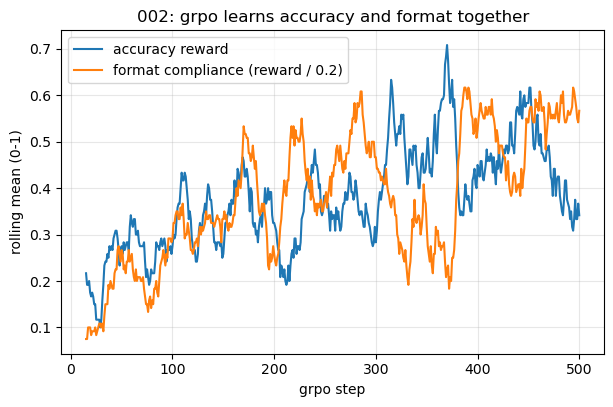

In [2]:
# the run in one picture: accuracy reward climbs, format saturates
fig, ax = plt.subplots(figsize=(7, 4.2))
x, acc = series(g2, "rewards/accuracy_reward/mean")
_, fmt = series(g2, "rewards/format_reward/mean")
w = 15
ax.plot(x[w - 1:], smooth(acc, w), label="accuracy reward")
ax.plot(x[w - 1:], smooth(fmt, w) / 0.2, label="format compliance (reward / 0.2)")
ax.set_xlabel("grpo step"); ax.set_ylabel("rolling mean (0-1)")
ax.set_title("002: grpo learns accuracy and format together")
ax.legend(); ax.grid(alpha=0.3)
save(fig, "fig01_grpo_reward_curves")
plt.show()

saved fig02_clipped_ratio_001_vs_002


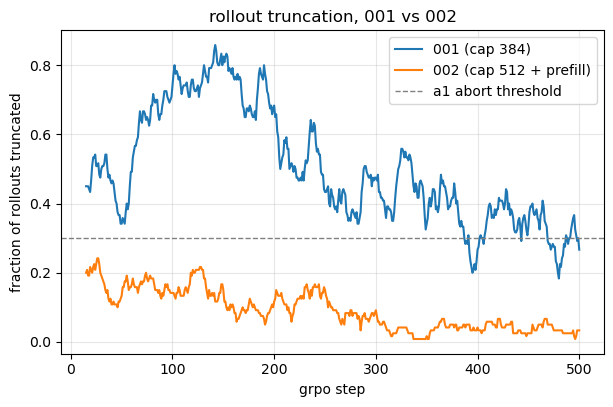

In [3]:
# the a1 story: 001 trained mostly truncated, 002 barely at all
fig, ax = plt.subplots(figsize=(7, 4.2))
for log, lbl in [(g1, "001 (cap 384)"), (g2, "002 (cap 512 + prefill)")]:
    x, y = series(log, "completions/clipped_ratio")
    ax.plot(x[14:], smooth(y), label=lbl)
ax.axhline(0.3, ls="--", c="grey", lw=1, label="a1 abort threshold")
ax.set_xlabel("grpo step"); ax.set_ylabel("fraction of rollouts truncated")
ax.set_title("rollout truncation, 001 vs 002")
ax.legend(); ax.grid(alpha=0.3)
save(fig, "fig02_clipped_ratio_001_vs_002")
plt.show()

saved fig03_completion_length


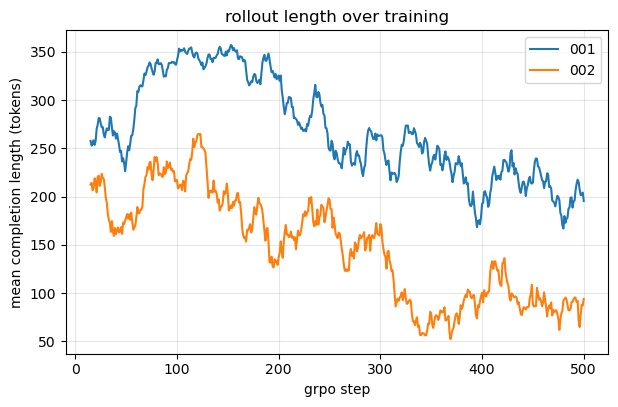

In [4]:
# completion length: both runs learn brevity, 002 without the truncation squeeze
fig, ax = plt.subplots(figsize=(7, 4.2))
for log, lbl in [(g1, "001"), (g2, "002")]:
    x, y = series(log, "completions/mean_length")
    ax.plot(x[14:], smooth(y), label=lbl)
ax.set_xlabel("grpo step"); ax.set_ylabel("mean completion length (tokens)")
ax.set_title("rollout length over training")
ax.legend(); ax.grid(alpha=0.3)
save(fig, "fig03_completion_length")
plt.show()

saved fig04_kl


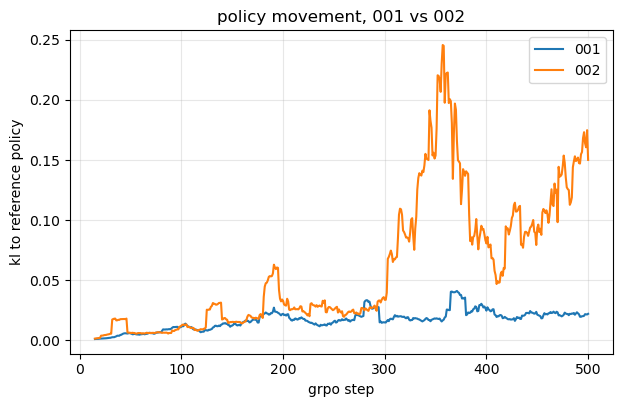

In [5]:
# kl vs the sft reference: 002 actually moves the policy
fig, ax = plt.subplots(figsize=(7, 4.2))
for log, lbl in [(g1, "001"), (g2, "002")]:
    x, y = series(log, "kl")
    ax.plot(x[14:], smooth(y), label=lbl)
ax.set_xlabel("grpo step"); ax.set_ylabel("kl to reference policy")
ax.set_title("policy movement, 001 vs 002")
ax.legend(); ax.grid(alpha=0.3)
save(fig, "fig04_kl")
plt.show()

saved fig05_sft_loss


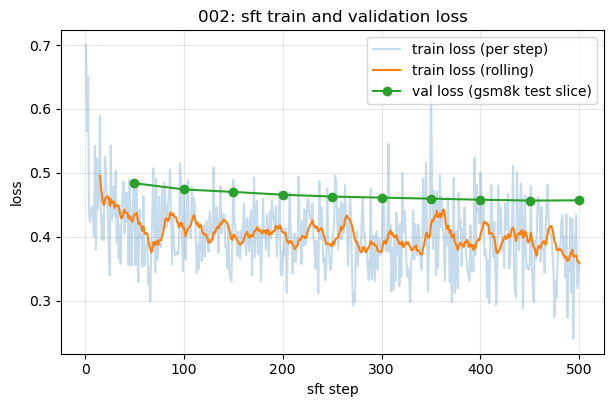

In [6]:
# sft looks healthy: train loss falls, val loss follows, no overfit
fig, ax = plt.subplots(figsize=(7, 4.2))
xt, yt = series(s2, "loss")
xv = [r["step"] for r in s2 if "eval_loss" in r]
yv = [r["eval_loss"] for r in s2 if "eval_loss" in r]
ax.plot(xt, yt, alpha=0.25, label="train loss (per step)")
ax.plot(xt[14:], smooth(yt), label="train loss (rolling)")
ax.plot(xv, yv, "o-", label="val loss (gsm8k test slice)")
ax.set_xlabel("sft step"); ax.set_ylabel("loss")
ax.set_title("002: sft train and validation loss")
ax.legend(); ax.grid(alpha=0.3)
save(fig, "fig05_sft_loss")
plt.show()

## 2. The headline results

The dotted lines show the pretrained model’s accuracy when it chooses among the four
answer letters. The original plot labels this score ‘knowledge ceiling’. Generated answers
can exceed this score.

saved fig06_headline_ceiling


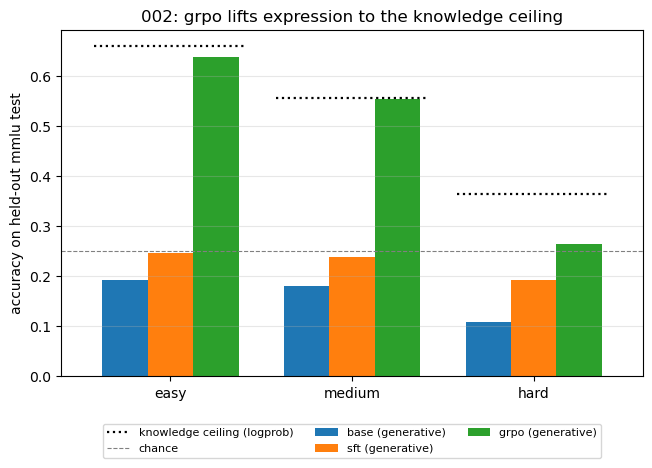

In [7]:
# Per tier accuracy by condition, with the knowledge ceiling drawn on top.
# GRPO reaches the ceiling on easy and medium, the hard gap stays open
fig, ax = plt.subplots(figsize=(7.5, 4.5))
xpos = np.arange(len(TIERS))
width = 0.25
for i, c in enumerate(COND):
    vals = [evals2[c]["per_tier_acc"][t] for t in TIERS]
    ax.bar(xpos + (i - 1) * width, vals, width, label=f"{c} (generative)")
for i, t in enumerate(TIERS):
    ax.hlines(lp2["base"]["per_tier_acc"][t], i - 0.42, i + 0.42, colors="black", ls=":", lw=1.6)
ax.hlines(lp2["base"]["per_tier_acc"]["hard"], 10, 11, colors="black", ls=":", lw=1.6, label="knowledge ceiling (logprob)")
ax.axhline(0.25, color="grey", lw=0.8, ls="--", label="chance")
ax.set_xlim(-0.6, 2.6)
ax.set_xticks(xpos); ax.set_xticklabels(TIERS)
ax.set_ylabel("accuracy on held-out mmlu test")
ax.set_title("002: grpo lifts expression to the knowledge ceiling")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8)
ax.grid(alpha=0.3, axis="y")
save(fig, "fig06_headline_ceiling")
plt.show()

saved fig07_delta_ci


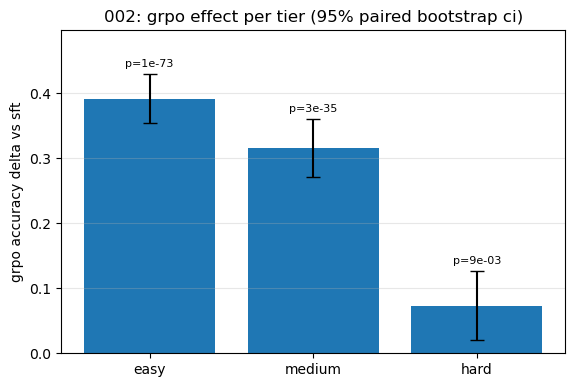

In [8]:
# grpo delta vs sft with paired bootstrap cis and mcnemar p values
from analysis.stats import paired_delta_ci, mcnemar_exact

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ds, errs, ps = [], [[], []], []
for t in TIERS:
    a = [r["correct"] for r in preds2["sft"] if r["tier"] == t]
    b = [r["correct"] for r in preds2["grpo"] if r["tier"] == t]
    d, lo, hi = paired_delta_ci(a, b, seed=0)
    n01 = sum(1 for u, v in zip(a, b) if u and not v)
    n10 = sum(1 for u, v in zip(a, b) if not u and v)
    ds.append(d); errs[0].append(d - lo); errs[1].append(hi - d)
    ps.append(mcnemar_exact(n01, n10))
ax.bar(TIERS, ds, yerr=errs, capsize=5)
for i, (d, p) in enumerate(zip(ds, ps)):
    ax.annotate(f"p={p:.0e}", (i, d + errs[1][i]), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom", fontsize=8)
ax.margins(y=0.16)
ax.set_ylabel("grpo accuracy delta vs sft")
ax.set_title("002: grpo effect per tier (95% paired bootstrap ci)")
ax.grid(alpha=0.3, axis="y")
save(fig, "fig07_delta_ci")
plt.show()

saved fig08_format_extraction


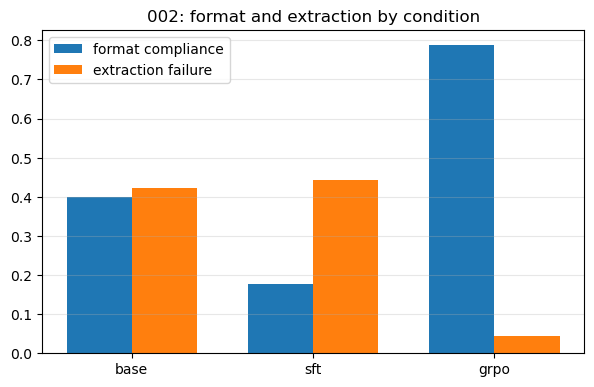

In [9]:
# what changed mechanically: compliance up, extraction failures nearly gone
fig, ax = plt.subplots(figsize=(7, 4.2))
xpos = np.arange(len(COND))
ax.bar(xpos - 0.18, [evals2[c]["format_compliance"] for c in COND], 0.36, label="format compliance")
ax.bar(xpos + 0.18, [evals2[c]["extraction_failure_rate"] for c in COND], 0.36, label="extraction failure")
ax.set_xticks(xpos); ax.set_xticklabels(COND)
ax.set_title("002: format and extraction by condition")
ax.legend(); ax.grid(alpha=0.3, axis="y")
save(fig, "fig08_format_extraction")
plt.show()

## 3. What the model actually writes

saved fig09_length_hist


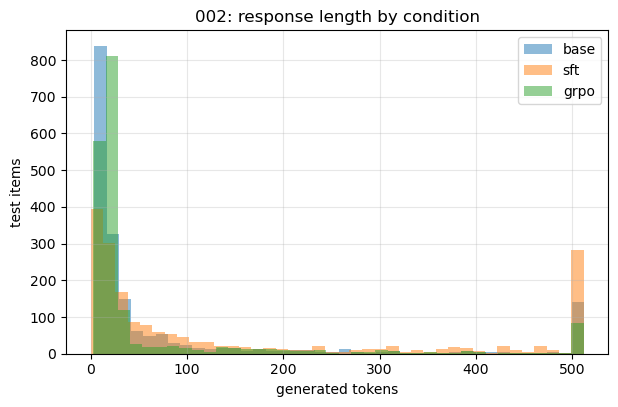

In [10]:
# response length distributions per condition
fig, ax = plt.subplots(figsize=(7, 4.2))
for c in COND:
    ax.hist([r["n_tokens"] for r in preds2[c]], bins=40, alpha=0.5, label=c)
ax.set_xlabel("generated tokens"); ax.set_ylabel("test items")
ax.set_title("002: response length by condition")
ax.legend(); ax.grid(alpha=0.3)
save(fig, "fig09_length_hist")
plt.show()

saved fig10_think_length


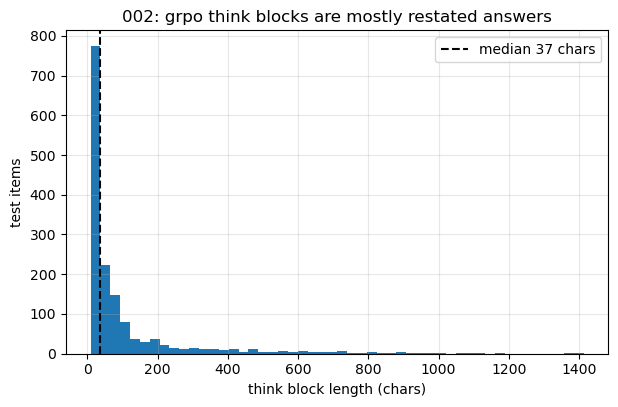

In [11]:
# How much thinking is in the think block. Spoiler: not much, its mostly
# a restated answer, which is the vestigial reasoning finding from the memo
lens = []
for r in preds2["grpo"]:
    m = re.search(r"(.*?)</think>", "<think>" + r["output"], re.DOTALL)
    if m:
        lens.append(len(m.group(1).replace("<think>", "").strip()))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.hist(lens, bins=50)
ax.axvline(np.median(lens), c="black", ls="--", label=f"median {np.median(lens):.0f} chars")
ax.set_xlabel("think block length (chars)"); ax.set_ylabel("test items")
ax.set_title("002: grpo think blocks are mostly restated answers")
ax.legend(); ax.grid(alpha=0.3)
save(fig, "fig10_think_length")
plt.show()

saved fig11_per_subject_delta


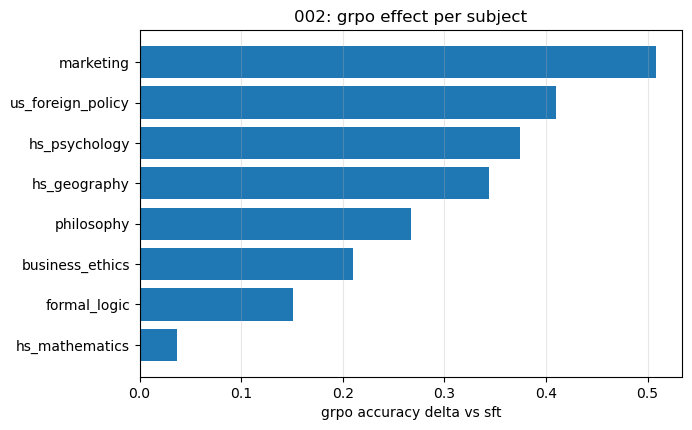

In [12]:
# per subject view of the grpo effect, sorted
subs = list(evals2["sft"]["per_subject_acc"])
deltas = [evals2["grpo"]["per_subject_acc"][s] - evals2["sft"]["per_subject_acc"][s] for s in subs]
order = np.argsort(deltas)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh([subs[i].replace("high_school_", "hs_") for i in order], [deltas[i] for i in order])
ax.set_xlabel("grpo accuracy delta vs sft")
ax.set_title("002: grpo effect per subject")
ax.grid(alpha=0.3, axis="x")
save(fig, "fig11_per_subject_delta")
plt.show()

## 4. Compute

saved fig12_stage_cost


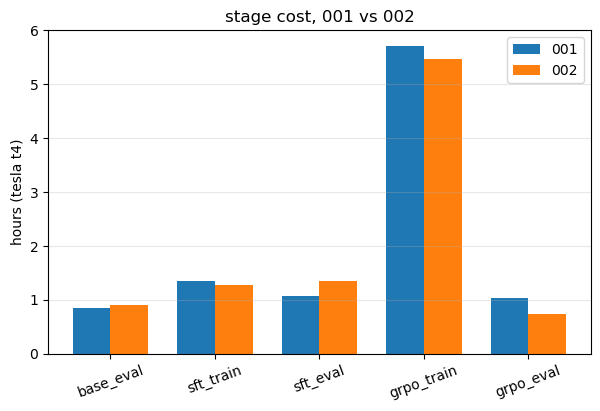

In [13]:
# where the gpu hours went, both experiments
stages = ["base_eval", "sft_train", "sft_eval", "grpo_train", "grpo_eval"]
fig, ax = plt.subplots(figsize=(7, 4.2))
xpos = np.arange(len(stages))
t1 = [man1["timings_sec"].get(s, 0) / 3600 for s in stages]
t2 = [man2["timings_sec"].get(s, 0) / 3600 for s in stages]
# 001s manifest has no base_eval timing (it ran in an earlier crashed cell), fill from the log: 50m20s
if t1[0] == 0:
    t1[0] = 3020 / 3600
ax.bar(xpos - 0.18, t1, 0.36, label="001")
ax.bar(xpos + 0.18, t2, 0.36, label="002")
ax.set_xticks(xpos); ax.set_xticklabels(stages, rotation=20)
ax.set_ylabel("hours (tesla t4)")
ax.set_title("stage cost, 001 vs 002")
ax.legend(); ax.grid(alpha=0.3, axis="y")
save(fig, "fig12_stage_cost")
plt.show()

## 5. Metrics tables

Every number in one place for the 0.5b run, computed straight from the saved json. If a
memo and a table ever disagree, trust the table. Pandas renders these inline.

In [14]:
import pandas as pd

# accuracy: generative exact-match per tier plus overall, and the log-prob knowledge probe
def gen_overall(c):
    return float(np.mean([r["correct"] for r in preds2[c]]))
rows = []
for c in COND:
    e = evals2[c]["per_tier_acc"]; k = lp2[c]["per_tier_acc"]
    rows.append({"condition": c, "gen_easy": e["easy"], "gen_med": e["medium"], "gen_hard": e["hard"],
                 "gen_overall": gen_overall(c),
                 "know_easy": k["easy"], "know_med": k["medium"], "know_hard": k["hard"]})
acc_tbl = pd.DataFrame(rows).set_index("condition").round(3)
print("accuracy: generative and knowledge probe, per tier")
display(acc_tbl)

# eval diagnostics
rows = []
for c in COND:
    ev = evals2[c]
    rows.append({"condition": c, "format_ok": ev["format_compliance"],
                 "extract_fail": ev["extraction_failure_rate"], "mean_len_tok": ev["mean_len"]})
diag_tbl = pd.DataFrame(rows).set_index("condition").round(3)
print("eval diagnostics")
display(diag_tbl)

accuracy: generative and knowledge probe, per tier


,gen_easy,gen_med,gen_hard,gen_overall,know_easy,know_med,know_hard
condition,,,,,,,
base,0.193,0.181,0.109,0.171,0.659,0.557,0.364
sft,0.247,0.238,0.192,0.232,0.646,0.567,0.359
grpo,0.638,0.553,0.265,0.532,0.660,0.558,0.361


eval diagnostics


,format_ok,extract_fail,mean_len_tok
condition,,,
base,0.399,0.422,84.418
sft,0.177,0.444,154.451
grpo,0.787,0.043,63.899


In [15]:
# GRPO training endpoints. Reward is on the 246 training prompts, not the held-out test.
# KL per step is noisy so kl_late50 is the mean of the last 50 steps, kl_median the whole run
def tail(L, key, k=20):
    ys = [r[key] for r in L if key in r]
    return float(np.mean(ys[-k:])) if ys else float("nan")
def head(L, key, k=20):
    ys = [r[key] for r in L if key in r]
    return float(np.mean(ys[:k])) if ys else float("nan")
def med(L, key):
    ys = [r[key] for r in L if key in r]
    return float(np.median(ys)) if ys else float("nan")
row = {"acc_reward_start": head(g2, "rewards/accuracy_reward/mean"),
       "acc_reward_end": tail(g2, "rewards/accuracy_reward/mean"),
       "fmt_reward_end": tail(g2, "rewards/format_reward/mean"),
       "clipped_end": tail(g2, "completions/clipped_ratio"),
       "comp_len_end": tail(g2, "completions/mean_length"),
       "kl_late50": tail(g2, "kl", 50), "kl_median": med(g2, "kl"),
       "frac_zero_std_late": tail(g2, "frac_reward_zero_std", 50)}
grpo_tbl = pd.DataFrame([row], index=["0.5b"]).round(4)
print("grpo training endpoints")
display(grpo_tbl)

# grpo gain over sft per tier: point delta, paired bootstrap ci, mcnemar exact p, discordants
from analysis.stats import paired_delta_ci, mcnemar_exact
rows = []
for t in TIERS:
    a = [r["correct"] for r in preds2["sft"] if r["tier"] == t]
    b = [r["correct"] for r in preds2["grpo"] if r["tier"] == t]
    d, lo, hi = paired_delta_ci(a, b, seed=0)
    n01 = sum(1 for u, v in zip(a, b) if u and not v)
    n10 = sum(1 for u, v in zip(a, b) if not u and v)
    rows.append({"tier": t, "delta": d, "ci_lo": lo, "ci_hi": hi,
                 "mcnemar_p": mcnemar_exact(n01, n10), "n_sft_only": n01, "n_grpo_only": n10})
delta_tbl = pd.DataFrame(rows).set_index("tier").round(4)
print("grpo accuracy gain over sft, per tier")
display(delta_tbl)

grpo training endpoints


,acc_reward_start,acc_reward_end,fmt_reward_end,clipped_end,comp_len_end,kl_late50,kl_median,frac_zero_std_late
0.5b,0.1812,0.3625,0.1113,0.0312,84.725,0.1323,0.0207,0.0


grpo accuracy gain over sft, per tier


,delta,ci_lo,ci_hi,mcnemar_p,n_sft_only,n_grpo_only
tier,,,,,,
easy,0.3914,0.3538,0.4289,0.0000,36,380
medium,0.3153,0.2709,0.3596,0.0000,36,228
hard,0.0732,0.0202,0.1263,0.0087,43,72


In [16]:
# compute hours per stage, and per subject accuracy with the grpo gain over sft
ts = man2["timings_sec"]
compute_tbl = pd.DataFrame([{**{k: v / 3600 for k, v in ts.items()}, "total_h": sum(ts.values()) / 3600}],
                           index=["0.5b"]).round(2)
print("compute hours per stage (tesla t4)")
display(compute_tbl)

rows = []
for s in evals2["grpo"]["per_subject_acc"]:
    rows.append({"subject": s, "base": evals2["base"]["per_subject_acc"][s],
                 "sft": evals2["sft"]["per_subject_acc"][s], "grpo": evals2["grpo"]["per_subject_acc"][s],
                 "grpo_minus_sft": evals2["grpo"]["per_subject_acc"][s] - evals2["sft"]["per_subject_acc"][s]})
subj_tbl = pd.DataFrame(rows).set_index("subject").round(3)
print("per subject accuracy and grpo gain over sft")
display(subj_tbl)

compute hours per stage (tesla t4)


,base_eval,base_logprob_eval,sft_train,sft_eval,sft_logprob_eval,grpo_train,grpo_eval,grpo_logprob_eval,total_h
0.5b,0.91,0.03,1.27,1.34,0.04,5.47,0.74,0.04,9.84


per subject accuracy and grpo gain over sft


,base,sft,grpo,grpo_minus_sft
subject,,,,
high_school_psychology,0.202,0.248,0.622,0.374
marketing,0.197,0.244,0.752,0.509
business_ethics,0.140,0.250,0.460,0.210
high_school_geography,0.136,0.237,0.581,0.343
philosophy,0.177,0.215,0.482,0.267
us_foreign_policy,0.280,0.310,0.720,0.410
high_school_mathematics,0.081,0.196,0.233,0.037
formal_logic,0.167,0.183,0.333,0.151


## 6. Accuracy overview (the tables as plots)

The section 5 accuracy table as grouped bars: generative on the left, knowledge probe on
the right, bars are base / sft / grpo across the tiers plus an overall, each labelled with
its value. The grey dashed line is 4-way chance (.25).

saved fig13_accuracy_overview


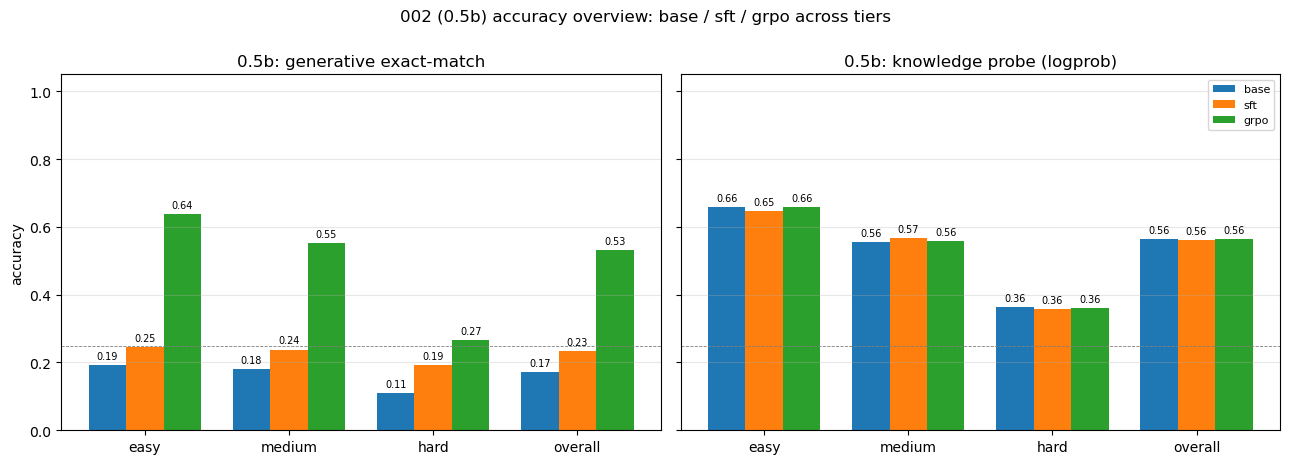

In [17]:
# accuracy overview as grouped bars, generative and knowledge side by side
def tier_counts():
    c = {}
    for r in preds2["base"]:
        c[r["tier"]] = c.get(r["tier"], 0) + 1
    return c
def gen_vals(cond):
    e = evals2[cond]["per_tier_acc"]
    ov = float(np.mean([r["correct"] for r in preds2[cond]]))
    return [e["easy"], e["medium"], e["hard"], ov]
def know_vals(cond):
    k = lp2[cond]["per_tier_acc"]
    n = tier_counts(); tot = sum(n.values())
    ov = sum(k[t] * n[t] for t in TIERS) / tot
    return [k["easy"], k["medium"], k["hard"], ov]

groups = ["easy", "medium", "hard", "overall"]
xpos = np.arange(len(groups)); width = 0.26
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, title, fn in [(axes[0], "generative exact-match", gen_vals), (axes[1], "knowledge probe (logprob)", know_vals)]:
    for i, c in enumerate(COND):
        vals = fn(c)
        bars = ax.bar(xpos + (i - 1) * width, vals, width, label=c)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.2f}", ha="center", va="bottom", fontsize=7)
    ax.axhline(0.25, color="grey", lw=0.6, ls="--")
    ax.set_ylim(0, 1.05); ax.set_xticks(xpos); ax.set_xticklabels(groups)
    ax.set_title(f"0.5b: {title}"); ax.grid(alpha=0.3, axis="y")
axes[1].legend(loc="upper right", fontsize=8); axes[0].set_ylabel("accuracy")
fig.suptitle("002 (0.5b) accuracy overview: base / sft / grpo across tiers", y=1.0)
fig.tight_layout()
save(fig, "fig13_accuracy_overview")
plt.show()

## 7. Eval diagnostics (as plots)

Format compliance, extraction failure rate and mean response length by condition. Lengths
are tokens so they keep their own panel. GRPO pushes compliance up and failure and length down.

saved fig14_eval_diagnostics


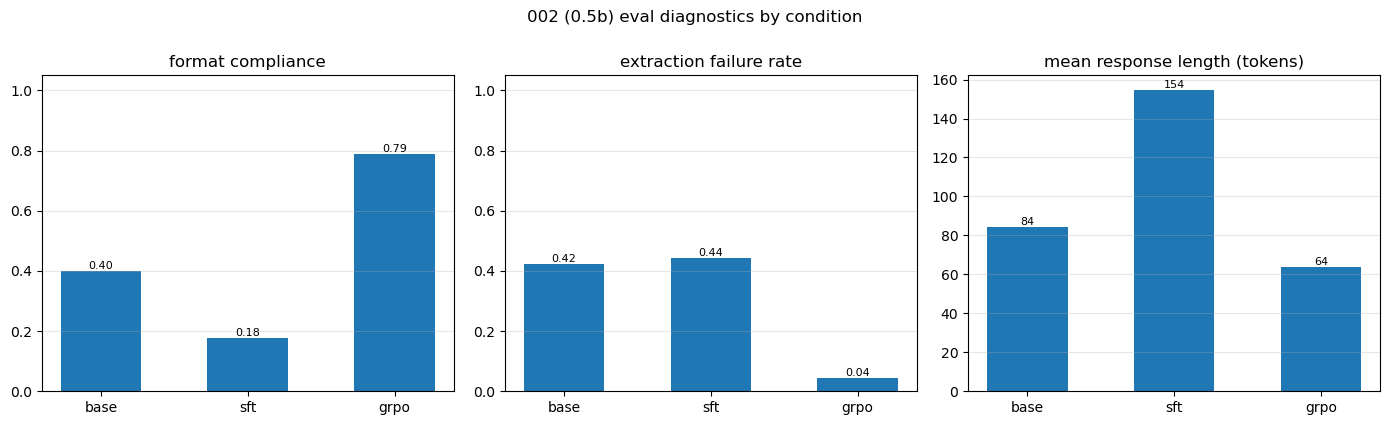

In [18]:
# eval diagnostics as bars, one panel per metric
metrics = [("format_compliance", "format compliance"),
           ("extraction_failure_rate", "extraction failure rate"),
           ("mean_len", "mean response length (tokens)")]
xpos = np.arange(len(COND)); width = 0.55
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (key, title) in zip(axes, metrics):
    vals = [evals2[c][key] for c in COND]
    bars = ax.bar(xpos, vals, width, color="tab:blue")
    for b, v in zip(bars, vals):
        lab = f"{v:.0f}" if key == "mean_len" else f"{v:.2f}"
        ax.text(b.get_x() + b.get_width() / 2, v, lab, ha="center", va="bottom", fontsize=8)
    ax.set_xticks(xpos); ax.set_xticklabels(COND); ax.set_title(title); ax.grid(alpha=0.3, axis="y")
    if key != "mean_len":
        ax.set_ylim(0, 1.05)
fig.suptitle("002 (0.5b) eval diagnostics by condition", y=1.0)
fig.tight_layout()
save(fig, "fig14_eval_diagnostics")
plt.show()

## 8. Optional: checkpoint trajectory (needs GPU time)

The ten 50-step grpo checkpoints live on google drive under
`inm363/checkpoints/002_COLAB_FULL_B05_sft_grpo_seed0/grpo/checkpoint-*`.
Plotting held-out accuracy against training step means running the generative eval
once per checkpoint, which is a colab job (roughly 45 min each on a t4), not a laptop one.
The cell below only lists what is there; flip RUN_LOGPROB_TRAJECTORY to true for a cheap
knowledge-probe trajectory on the drive mount (a few minutes per checkpoint on apple silicon,
but the probe was flat in 001 and 002, so I expect a flat line, thats the point of it).

In [19]:
# find the checkpoints on the drive mount, list only by default
import glob

RUN_LOGPROB_TRAJECTORY = False

drive = None
for cand in glob.glob(str(Path.home() / "Library/CloudStorage/GoogleDrive-*/My Drive/inm363")) + [str(Path.home() / "Google Drive/My Drive/inm363")]:
    if Path(cand).is_dir():
        drive = Path(cand)
        break
if drive:
    ckpts = sorted(glob.glob(str(drive / "checkpoints/002_COLAB_FULL_B05_sft_grpo_seed0/grpo/checkpoint-*")))
    print("drive:", drive)
    print("grpo checkpoints found:", [Path(c).name for c in ckpts])
else:
    print("no drive mount found, pass the path by hand if needed")

if RUN_LOGPROB_TRAJECTORY and drive and ckpts:
    # knowledge probe per checkpoint on a subset, cheap but needs torch + the model
    from config import load_config
    from eval.harness import run_logprob_eval  # heavy imports live inside
    print("this evaluates each checkpoint with the logprob probe, go make a tea")

drive: /Users/oleggastov/Library/CloudStorage/GoogleDrive-gogastov@gmail.com/My Drive/inm363
grpo checkpoints found: ['checkpoint-100', 'checkpoint-150', 'checkpoint-200', 'checkpoint-250', 'checkpoint-300', 'checkpoint-350', 'checkpoint-400', 'checkpoint-450', 'checkpoint-50', 'checkpoint-500']
